# 04 — Data Visualizations (ChargeWise Karnataka Insights)

Produces four publication-quality, question-driven figures saved in `notebooks/figures/`:
1. **District & Operator Distribution** — Identifies Bengaluru clustering vs highway corridor operators.
2. **Charging Power & Charging Type Distribution** — Exposes how many public points lack rated DC fast-charging power.
3. **Karnataka Spatial Distribution Map** — Highlights the Mysuru → Madikeri → Puttur → Mangaluru corridor relative to statewide coverage.
4. **Karnataka EV Sales & Penetration Trajectory (2021–2024)** — Compares 2-Wheeler vs 4-Wheeler adoption velocity.

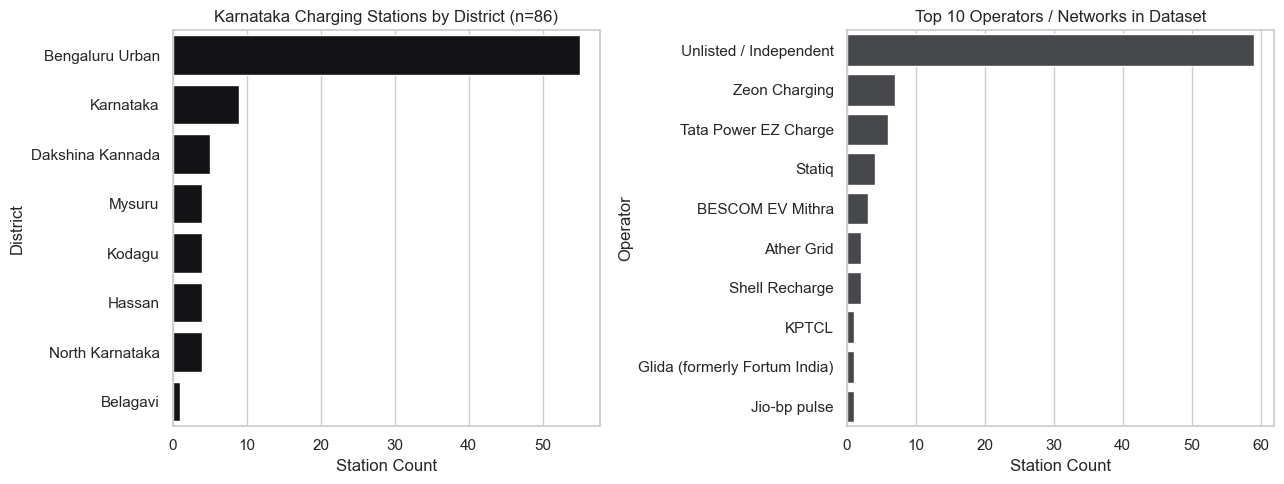

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")
REPO = Path("..").resolve()
PROC = REPO / "data" / "processed"
FIG = REPO / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

stations = pd.read_csv(PROC / "karnataka_stations_clean.csv")
ka_sales = pd.read_csv(PROC / "karnataka_ev_sales_clean.csv", parse_dates=["date_parsed"])

# Palette aligned with ChargeWise monochrome-slate theme
DARK = "#121317"
SLATE = "#45474D"
MUTED = "#6A6A71"
ACCENT = "#B7BFD9"

# 1. District & Operator Distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
dist_counts = stations["district"].value_counts()
sns.barplot(x=dist_counts.values, y=dist_counts.index, ax=axes[0], color=DARK)
axes[0].set_title("Karnataka Charging Stations by District (n=86)")
axes[0].set_xlabel("Station Count")
axes[0].set_ylabel("District")

op_counts = stations["operator"].value_counts().head(10)
sns.barplot(x=op_counts.values, y=op_counts.index, ax=axes[1], color=SLATE)
axes[1].set_title("Top 10 Operators / Networks in Dataset")
axes[1].set_xlabel("Station Count")
axes[1].set_ylabel("Operator")
plt.tight_layout()
plt.savefig(FIG / "fig1_stations_by_district_and_operator.png", dpi=150)
plt.show()

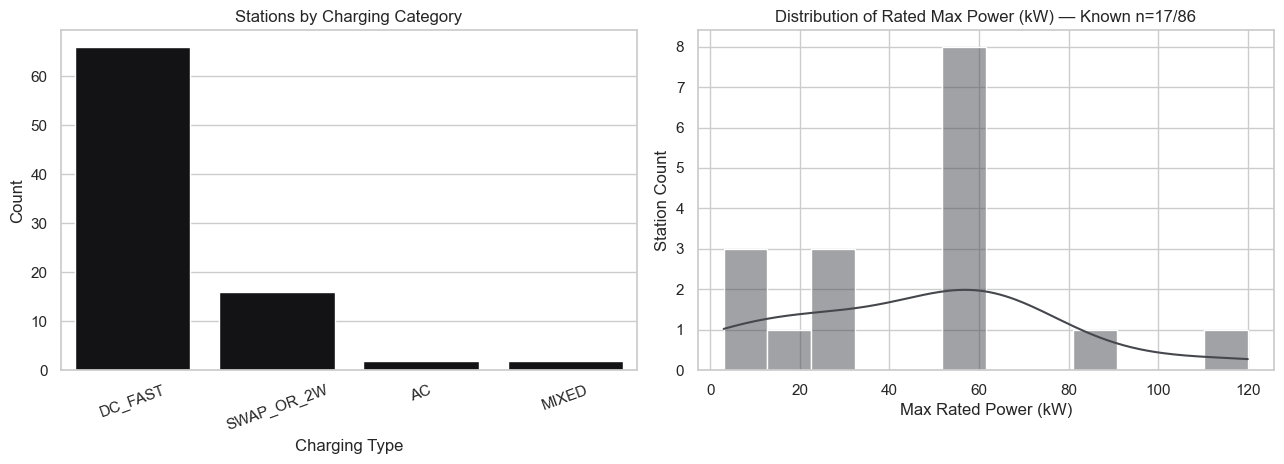

In [2]:
# 2. Charging Type & Power Rating Distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ct_counts = stations["charging_type"].value_counts()
sns.barplot(x=ct_counts.index, y=ct_counts.values, ax=axes[0], color=DARK)
axes[0].set_title("Stations by Charging Category")
axes[0].set_xlabel("Charging Type")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=20)

known_power = stations["max_power_kw"].dropna()
sns.histplot(known_power, bins=12, kde=True, ax=axes[1], color=SLATE)
axes[1].set_title(f"Distribution of Rated Max Power (kW) — Known n={len(known_power)}/{len(stations)}")
axes[1].set_xlabel("Max Rated Power (kW)")
axes[1].set_ylabel("Station Count")
plt.tight_layout()
plt.savefig(FIG / "fig2_charging_power_and_type_distribution.png", dpi=150)
plt.show()

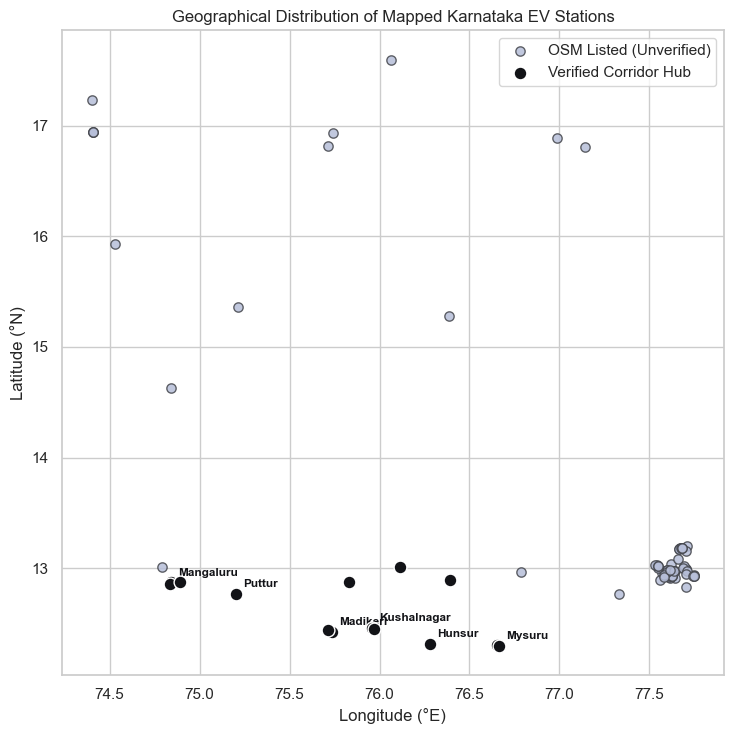

In [3]:
# 3. Geographic Distribution Across Karnataka (Highlighting Mysuru -> Mangaluru Corridor)
fig, ax = plt.subplots(figsize=(7.5, 7.5))
listed = stations[~stations["is_verified_tier"]]
verified = stations[stations["is_verified_tier"]]

ax.scatter(listed["longitude"], listed["latitude"], s=45, c=ACCENT, edgecolors=SLATE, alpha=0.85, label="OSM Listed (Unverified)")
ax.scatter(verified["longitude"], verified["latitude"], s=85, c=DARK, edgecolors="#FFFFFF", linewidth=1.0, label="Verified Corridor Hub", zorder=4)

# Annotate Mysuru -> Mangaluru key nodes
corridor_labels = {
    "Mysuru": (76.6646, 12.2978),
    "Hunsur": (76.2820, 12.3115),
    "Kushalnagar": (75.9590, 12.4580),
    "Madikeri": (75.7382, 12.4244),
    "Puttur": (75.2018, 12.7633),
    "Mangaluru": (74.8425, 12.8714),
}
for city, (lon, lat) in corridor_labels.items():
    ax.annotate(city, (lon, lat), xytext=(5, 5), textcoords="offset points", fontsize=8.5, fontweight="bold", color=DARK)

ax.set_title("Geographical Distribution of Mapped Karnataka EV Stations")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG / "fig3_karnataka_spatial_map.png", dpi=150)
plt.show()

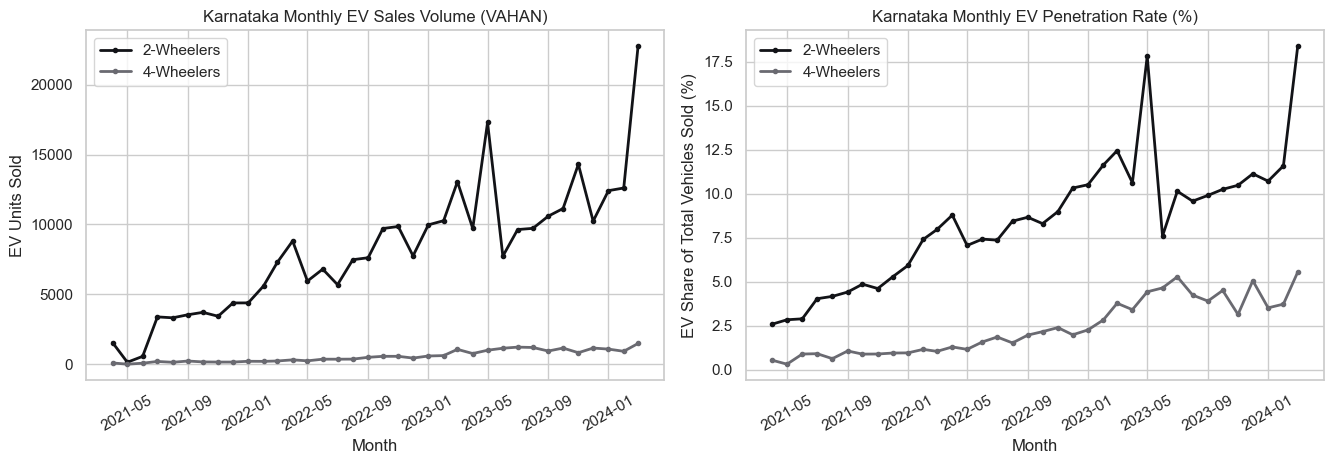

In [4]:
# 4. Karnataka Monthly EV Sales & Penetration Trend (2021-2024)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for cat, col in [("2-Wheelers", DARK), ("4-Wheelers", MUTED)]:
    sub = ka_sales[ka_sales["vehicle_category"] == cat].sort_values("date_parsed")
    axes[0].plot(sub["date_parsed"], sub["electric_vehicles_sold"], marker="o", markersize=3, linewidth=2, color=col, label=cat)
    axes[1].plot(sub["date_parsed"], sub["ev_penetration_pct"], marker="o", markersize=3, linewidth=2, color=col, label=cat)

axes[0].set_title("Karnataka Monthly EV Sales Volume (VAHAN)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("EV Units Sold")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=30)

axes[1].set_title("Karnataka Monthly EV Penetration Rate (%)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("EV Share of Total Vehicles Sold (%)")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(FIG / "fig4_karnataka_ev_sales_trend.png", dpi=150)
plt.show()